# Mudcard
- **"The lecture was helpful. But in the notes, at first, the mention of iloc for columns was confusing.**
'''# select columns by index using iloc
print(df_pd.iloc[:,3])'''
**Because previously it was mentioned for rows. Maybe just a quick note/comment emphasizing the purpose of the comma would clear up the immediate confusion?
ex, iloc[:3] vs iloc[:,3].**
    - Pandas/polars dataframes have rows and columns. The rows are indexed in the first location within the square brackets, the columns are indexed in the second location
    - so df.iloc[x,y] refers to the xth row and the yth column in df
    - we saw the same behavior with .shape because the output is a list with two numbers. the first number is the number of rows, the second number is the number of columns
    - If you find syntax unclear, you should look up the manual, come to office hours to talk to me of the TAs, or ask GenAI to explain it to you
- **I found argument expectations in pandas vs. polar to be the muddiest part today, specifically notice the small difference between similar functions in both libraries.**
    - That's perfectly normal, it will take some time to get used to it.
- **In a previous mudcard:**
'''How to develop supervised learning model with unstructured data?'''
**you responded**
'''Create structured data using the unstructured data. It works OK but model performance might not be great.'''
**Could you explain why?**
    - unstructured data like images, text, videos are rich datasets
    - when you try to convert unstructured data to structured tabular data, you often lose quite a bit of information
    - You can develop ML models with unstructured data but you need to use deep learning techniques
    - The ML models we cover in this class only work with structured data
- **1. How does "ignore_index" argument choose the index column to ignore? Is the first column of each dataset automatically chosen?**
    - Careful here, the pandas index column is separate from the data columns!
    - When you print a dataframe, it appears on the left side but it's not automatically the first column
    - Notice there is no column name printed above it.
    - so ignore_index doesn't ignore the first column of the dataframe, it resets the row indices
- **I had difficulties to understand merging datasets.**
    - Unfortunately we need to move on but I recommend that you read the manual, run the code yourself, come to office hours to talk to me or the TAs, or ask GenAI to explain the concept
- **What is the best way to determine whether we should use pandas or polars for merging a specific data set?**
    - It depends on the specific scenario.
    - If for example you need to perform the merge operation frequently on multiple files, you could perform merge using both pandas and polars and time the operation. whichever is faster, that's the approach you should use going forward
    - If you only need to merge once or not very frequently, it mostly depends on the dataset size.
        - for small to medium sized data, it doesn't really matter because we are talking about a difference of a fraction of a second in compute time
        - for large datasets, polars is usually faster
    - [here](https://stuffbyyuki.com/pandas-vs-polars-speed-comparison/) is an article on how you can measure compute time and compare approaches
- **How does one place that info on the features variables with the sine wave to represent seasonal data?**
    - It's called cyclic encoding, [here](https://scikit-learn.org/stable/auto_examples/applications/plot_cyclical_feature_engineering.html) is a sklearn article on it
- **- Is there a difference between using "df1.append(df2)" versus pd.concat([df1_pd,df2_pd],ignore_index=True)**
    - Yes! Print out both dataframes to see the difference.
- **"For the quiz, I used df3 = df_append.merge(df_append,how='right',on='subject_id') at first, which gave me an output that is slightly different from the output I saw in the lecture. The components of the merged dataframe is still the same, but test-id was put in a different column. Is that going to be an issue?**
    - it's usually not an issue if you refer to columns by column names rather than column indices
    - the column names are the same in both type of merges but as you noted the indices are different because the column locations change
- **Also, I am still not quite sure what ignore_index do.**
    - print out the merged dataframe with and without the ignore_index to figure it out

# <center> Lecture 4: Exploratory data analysis in python</center>

# The supervised ML pipeline

**0. Data collection/manipulation**: you might have multiple data sources and/or you might have more data than you need
   - you need to be able to read in datasets from various sources (like csv, excel, SQL, parquet, etc)
   - you need to be able to filter the columns/rows you need for your ML model
   - you need to be able to combine the datasets into one dataframe 

<span style="background-color: #FFFF00">**1. Exploratory Data Analysis (EDA)**: you need to understand your data and verify that it doesn't contain errors</span>
   - do as much EDA as you can!
    
**2. Split the data into different sets**: most often the sets are train, validation, and test (or holdout)
   - practitioners often make errors in this step!
   - you can split the data randomly, based on groups, based on time, or any other non-standard way if necessary to answer your ML question

**3. Preprocess the data**: ML models only work if X and Y are numbers! Some ML models additionally require each feature to have 0 mean and 1 standard deviation (standardized features)
   - often the original features you get contain strings (for example a gender feature would contain 'male', 'female', 'non-binary', 'unknown') which needs to be transformed into numbers
   - often the features are not standardized (e.g., age is between 0 and 100) but it needs to be standardized
    
**4. Choose an evaluation metric**: depends on the priorities of the stakeholders
   - often requires quite a bit of thinking and ethical considerations
     
**5. Choose one or more ML techniques**: it is highly recommended that you try multiple models
   - start with simple models like linear or logistic regression
   - try also more complex models like nearest neighbors, support vector machines, random forest, etc.
    
**6. Tune the hyperparameters of your ML models (aka cross-validation or hyperparameter tuning)**
   - ML techniques have hyperparameters that you need to optimize to achieve best performance
   - for each ML model, decide which parameters to tune and what values to try
   - loop through each parameter combination
       - train one model for each parameter combination
       - evaluate how well the model performs on the validation set
   - take the parameter combo that gives the best validation score
   - evaluate that model on the test set to report how well the model is expected to perform on previously unseen data
    
**7. Interpret your model**: black boxes are often not useful
   - check if your model uses features that make sense (excellent tool for debugging)
   - often model predictions are not enough, you need to be able to explain how the model arrived to a particular prediction (e.g., in health care)

# <center> Learning objectives </center>
### By the end of this lecture, you will be able to
   - group visualization tasks based on stakes vs. audience size
   - select appropriate figure type for visulizing one feature, two features, or multiple features simultaenously


## Let's start with some examples of visualizations

<center><img src="../figures/example1.png" width="600"></center>

<center><img src="../figures/example2.pn" width="600"></center>

<center><img src="../figures/example3.pn" width="600"></center>

<center><img src="../figures/example4.pn" width="600"></center>



### <font color='LIGHTGRAY'>By the end of this lecture, you will be able to</font>
   - **group visualization tasks based on stakes vs. audience size**
   - <font color='LIGHTGRAY'>select appropriate figure type for visulizing one feature, two features, or multiple features simultaenously</font>


## Data visualization is one of the most important tasks of a data scientist

- you might need to convey information to your team, executives, your peers at other companies or institutions, or the general public
- the amount of time and effort you should put into a figure depends on a couple of things:
    - the impact or stakes: How consequential it is if your target audience misunderstands the figure?
    - audience size: how many people will see your visualization?
- here is a useful 2x2: 

|                 | **Small audience**                    | **Large audience**                                             |
| --------------- | ------------------------------------- | -------------------------------------------------------------- |
| **Low impact**  | Internal/team analysis                | Routine public information like weather chart, website stats   |
| **High impact** | Executive/leadership decision support | Scientific publication, news article, reports and presentations|

- other useful categories:
    - exploratory figures: usually low stakes, it's unclear what the takeaway message of the figure is, you are still trying to figure it out
    - explanatory figures: usually high stakes, the message must be clear 

- advice for the final project:
    - you always start with exploratory figures
    - create a large number of them
    - find something interesting that you'd like to show to the audience in your report or final presentation
        - don't just describe what's on the x and y axes
        - think of punchy headlines as we have seen in the example figures
        - what is the message you'd like your audience to take away when looking at your figure?
        - what can you do to bring that message out and make it obvious?


### <font color='LIGHTGRAY'>By the end of this lecture, you will be able to</font>
   - <font color='LIGHTGRAY'>group visualization tasks based on stakes vs. audience size</font>
   - **select appropriate figure type for visulizing one feature, two features, or multiple features simultaenously**



## Dataset of the day

Adult dataset, see [here](https://archive.ics.uci.edu/ml/datasets/Adult)

## Packages of the day

matplotlib and pandas

## Data types
- **continuous data**: represented by floating point numbers usually (not always), it is a measured quantity with some unit of measurement (not always)
   - age measured in years
   - distance measured in km or miles
   - weight measured in kg or lbs
   - rates are dimensionless but usually continuous e.g., click-through rates
- **ordinal data**: not continuous data, there are a small number of categories and the categories can be ordered
   - satisfaction levels (satisfied, moderately satisfied, not satisfied)
   - ratings (1-5 stars or ratings like fair, average, good, excellent)
   - time categories like day of the week, month of the year
   - education level
- **categorical data**: there are a small number of categories and the categories cannot be ordered
   - demographic info like race, gender, or marital status
   - blood type
   - eye color
   - type of rock (igneous, sedimentary or metamorphic)

A feature's data type can sometimes be context-dependent or unclear! 
   - e.g., blood type could be considered ordinal in certain medical situations.
   - Would people's birth year be continuous or ordinal?

##  Let's load the data first!

In [1]:
import pandas as pd
import numpy as np
import matplotlib
from matplotlib import pylab as plt
df = pd.read_csv('../data/adult_data.csv')
print(df.dtypes) 

age               int64
workclass           str
fnlwgt            int64
education           str
education-num     int64
marital-status      str
occupation          str
relationship        str
race                str
sex                 str
capital-gain      int64
capital-loss      int64
hours-per-week    int64
native-country      str
gross-income        str
dtype: object


### Column is continuous

In [2]:
print(df['age'].describe())

count    32561.000000
mean        38.581647
std         13.640433
min         17.000000
25%         28.000000
50%         37.000000
75%         48.000000
max         90.000000
Name: age, dtype: float64


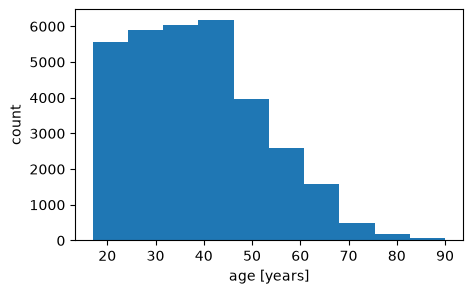

In [4]:
plt.figure(figsize=(5,3))

df['age'].plot.hist()   # bins = int(np.sqrt(df.shape[0])) 

                        # bins = df['age'].nunique()
plt.xlabel('age [years]')
plt.ylabel('count')
plt.show()

 what this line of code does? 
 
 bins = int(np.sqrt(df.shape[0]))


This line of code calculates the ideal number of bins to use when plotting a histogram for a dataset.
It implements a popular statistical guideline called Square-root choice, which suggests that the number of bins should be the square root of the total number of data points.

🧩 Code Breakdown

• df.shape[0]: Finds the total number of rows (data points) in your pandas DataFrame.
• np.sqrt(...): Uses the  to calculate the square root of that number.
• int(...): Converts the result into a whole number (integer) since you cannot have a fraction of a histogram bin.

📊 Example

If your DataFrame (df) has 100 rows:
1. df.shape[0] is 100
2. np.sqrt(100) is 10.0
3. int(10.0) gives you 10 bins

If your DataFrame has 150 rows:
1. df.shape[0] is 150
2. np.sqrt(150) is roughly 12.24
3. int(12.24) rounds down to give you 12 bins

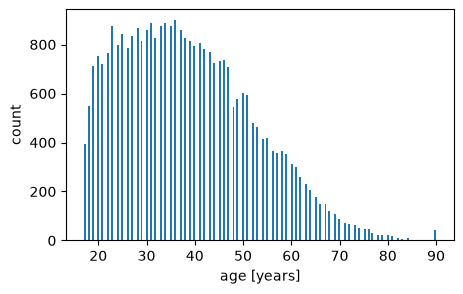

In [8]:
# my code for the same plot
plt.figure(figsize=(5,3))

df['age'].plot.hist(bins = int(np.sqrt(df.shape[0])))

# bins = df['age'].nunique()

plt.xlabel('age [years]')
plt.ylabel('count')
plt.show()

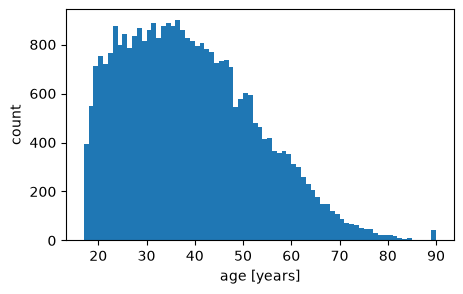

In [12]:
plt.figure(figsize=(5,3))

df['age'].plot.hist(bins = df['age'].nunique([0]))
#bins = df['age'].nunique()
plt.xlabel('age [years]')
plt.ylabel('count')
plt.show()

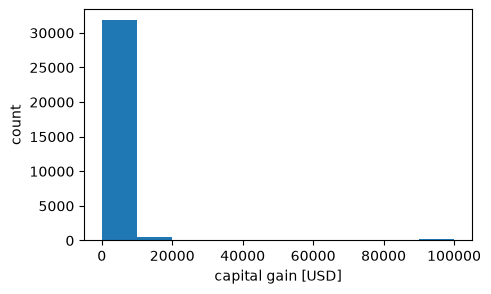

In [16]:
plt.figure(figsize=(5,3))

df['capital-gain'].plot.hist() # log=True, bins = np.logspace(np.log10(1),np.log10(np.max(df['capital-gain'])),50)
#plt.semilogy()
#plt.semilogx()
plt.xlabel('capital gain [USD]')
plt.ylabel('count')
plt.show()


### Column is categorical

In [17]:
print(df['occupation'].value_counts())

occupation
Prof-specialty       4140
Craft-repair         4099
Exec-managerial      4066
Adm-clerical         3770
Sales                3650
Other-service        3295
Machine-op-inspct    2002
?                    1843
Transport-moving     1597
Handlers-cleaners    1370
Farming-fishing       994
Tech-support          928
Protective-serv       649
Priv-house-serv       149
Armed-Forces            9
Name: count, dtype: int64


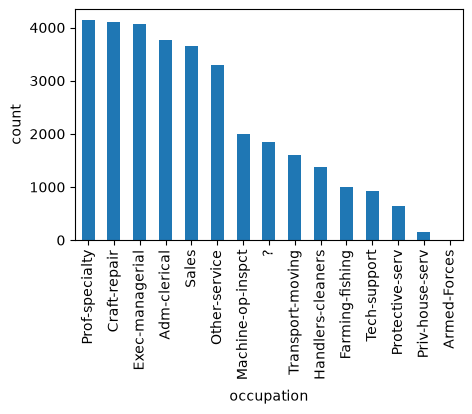

In [18]:
plt.figure(figsize=(5,3))
df['occupation'].value_counts().plot.bar() # .barh()
plt.ylabel('count')
plt.xlabel('occupation')
plt.show()

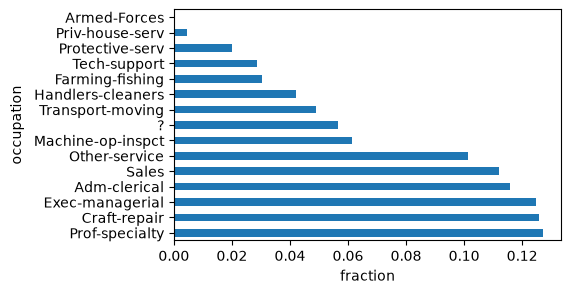

In [19]:
plt.figure(figsize=(5,3))
df['occupation'].value_counts(normalize=True).plot.barh()
plt.xlabel('fraction')
plt.show()

# Quiz 1
- What's wrong with this figure?

<center><img src="../figures/GA-graph-before.png" width="600"></center>


## Ordinal features

<center><img src="../figures/GA-graph-after.pn" width="600"></center>

- other examples of ordinal features:
    - measure of quality (e.g., bad, average, good, excellent)
    - socioeconomic status (e.g., low income, middle income, high income)
    - education level (e.g., 8th grade, high school, BSc, MSc, PhD)
    - satisfaction rating (e.g., dislike, neutral, like)
    - time (e.g., days of the week, months, years)
    

## The categories of an ordinal feature must be visualized in the correct order! 

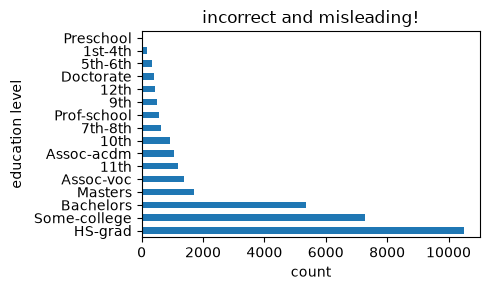

In [20]:
plt.figure(figsize=(5,3))
df['education'].value_counts().plot.barh()
plt.xlabel('count')
plt.ylabel('education level')
plt.title('incorrect and misleading!')
plt.tight_layout()
plt.show()

In [21]:
df['education'].value_counts()

education
HS-grad         10501
Some-college     7291
Bachelors        5355
Masters          1723
Assoc-voc        1382
11th             1175
Assoc-acdm       1067
10th              933
7th-8th           646
Prof-school       576
9th               514
12th              433
Doctorate         413
5th-6th           333
1st-4th           168
Preschool          51
Name: count, dtype: int64

In [22]:
correct_order = [' Preschool', ' 1st-4th', ' 5th-6th', ' 7th-8th', ' 9th', ' 10th', ' 11th', \
         ' 12th', ' HS-grad', ' Some-college', ' Assoc-voc', ' Assoc-acdm', ' Bachelors',\
         ' Masters', ' Prof-school', ' Doctorate']

df['education'].value_counts().reindex(correct_order)

education
Preschool          51
1st-4th           168
5th-6th           333
7th-8th           646
9th               514
10th              933
11th             1175
12th              433
HS-grad         10501
Some-college     7291
Assoc-voc        1382
Assoc-acdm       1067
Bachelors        5355
Masters          1723
Prof-school       576
Doctorate         413
Name: count, dtype: int64

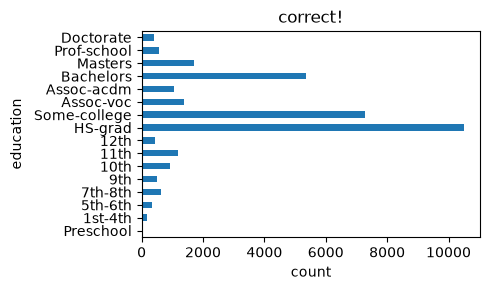

In [23]:
plt.figure(figsize=(5,3))

df['education'].value_counts().reindex(correct_order).plot.barh()
plt.xlabel('count')
plt.ylabel('education')
plt.title('correct!')
plt.tight_layout()
plt.show()

## Visualize column pairs

## <center> Overview </center>

| *Visualization types* | column continuous | column categorical |
| --- | :-: | :-: |
| __column continuous__    	| scatter plot, heatmap 	| category-specific histograms, box plot, violin plot |
| __column categorical__   	| category-specific histograms, box plot, violin plot |  stacked bar plot  	|


### Continuous vs. continuous columns
- scatter plot

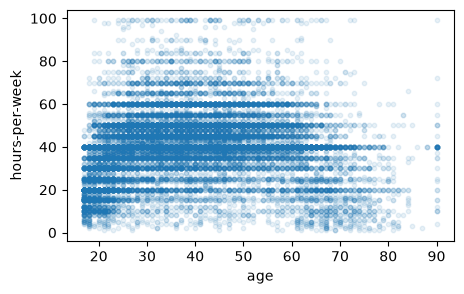

In [24]:
df.plot.scatter('age','hours-per-week',figsize=(5,3), alpha=0.1, s=10) # alpha=0.1,s=10---> makes the plots transparent 
plt.show()

### Continuous vs. continuous columns
- heatmap

In [25]:
nbins = 40

heatmap, xedges, yedges = np.histogram2d(df['age'], df['hours-per-week'], bins=nbins)
extent = [xedges[0], xedges[-1], yedges[0], yedges[-1]]

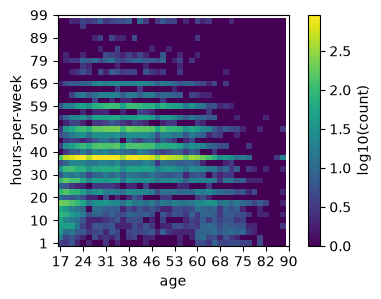

In [26]:
heatmap[heatmap == 0] = 0.1 # we will use log and log(0) is undefined
plt.figure(figsize=(5,3))

plt.imshow(np.log10(heatmap).T, origin='lower',vmin=0) # use log count
#plt.imshow(heatmap.T, origin='lower',vmin=0) # use log count
plt.xlabel('age')
plt.ylabel('hours-per-week')
plt.xticks(np.arange(nbins+1)[::4],xedges[::4].astype(int))
plt.yticks(np.arange(nbins+1)[::4],yedges[::4].astype(int))
plt.colorbar(label='log10(count)')
plt.show()

### Categorical vs. categorical columns
- stacked bar plot

In [27]:
count_matrix = df.groupby(['race', 'gross-income']).size().unstack()
print(count_matrix)

count_matrix_norm = count_matrix.div(count_matrix.sum(axis=1),axis=0)
print(count_matrix_norm)

gross-income        <=50K  >50K
race                           
Amer-Indian-Eskimo    275    36
Asian-Pac-Islander    763   276
Black                2737   387
Other                 246    25
White               20699  7117
gross-income           <=50K      >50K
race                                  
Amer-Indian-Eskimo  0.884244  0.115756
Asian-Pac-Islander  0.734360  0.265640
Black               0.876120  0.123880
Other               0.907749  0.092251
White               0.744140  0.255860


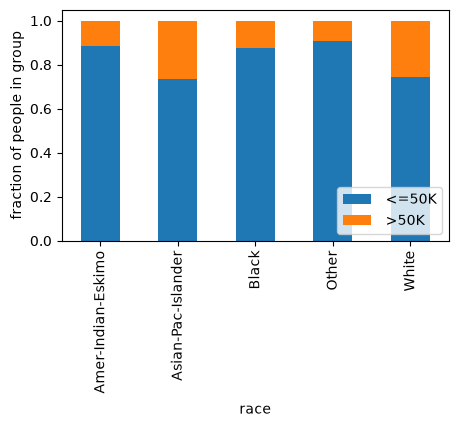

In [28]:
count_matrix_norm.plot(kind='bar', stacked=True,figsize=(5,3))
plt.ylabel('fraction of people in group')
plt.legend(loc=4)
plt.show()

### Continuous vs. categorical columns
- category-specific histograms

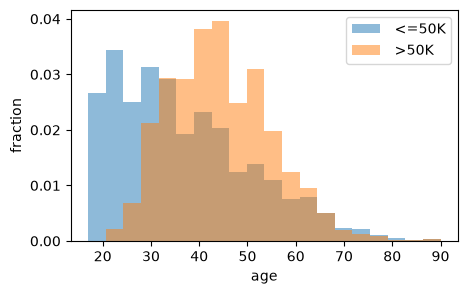

In [29]:
import matplotlib
from matplotlib import pylab as plt

categories = df['gross-income'].unique()
bin_range = (df['age'].min(),df['age'].max())

plt.figure(figsize=(5,3))

for c in categories:
    plt.hist(df[df['gross-income']==c]['age'],alpha=0.5,label=c,range=bin_range,bins=20,density=True)
plt.legend()
plt.ylabel('fraction')
plt.xlabel('age')
plt.show()

### Continuous vs. categorical columns
- box plot

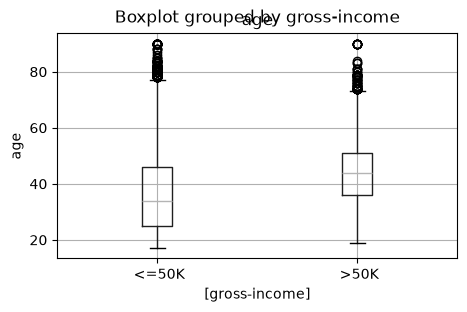

In [30]:
df[['age','gross-income']].boxplot(by='gross-income',figsize=(5,3))
plt.ylabel('age')
plt.show()

### Continuous vs. categorical columns
- violin plot

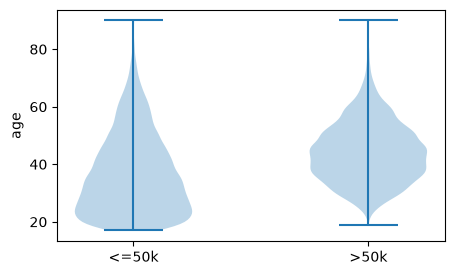

In [31]:
dataset = [df[df['gross-income']==' <=50K']['age'].values,
           df[df['gross-income']==' >50K']['age'].values]

plt.figure(figsize=(5,3))

plt.violinplot(dataset = dataset)
plt.xticks([1,2],['<=50k','>50k'])
plt.ylabel('age')
plt.show()

In [32]:
help(plt.violinplot)

Help on function violinplot in module matplotlib.pyplot:

violinplot(
    dataset: ArrayLike | Sequence[ArrayLike],
    positions: ArrayLike | None = None,
    *,
    vert: bool | None = None,
    orientation: Literal['vertical', 'horizontal'] = 'vertical',
    widths: float | ArrayLike = 0.5,
    showmeans: bool = False,
    showextrema: bool = True,
    showmedians: bool = False,
    quantiles: Sequence[float | Sequence[float]] | None = None,
    points: int = 100,
    bw_method: Literal['scott', 'silverman'] | float | Callable[[GaussianKDE], float] | None = None,
    side: Literal['both', 'low', 'high'] = 'both',
    facecolor: Sequence[ColorType] | ColorType | None = None,
    linecolor: Sequence[ColorType] | ColorType | None = None,
    data: DataParamType = None
) -> dict[str, Collection]
    Make a violin plot.

    Make a violin plot for each column of *dataset* or each vector in
    sequence *dataset*.  Each filled area extends to represent the
    entire data range, with opti

## Quiz 2
Pair the column name(s) with the appropriate visualization type!

## Visualize multiple columns simultaneously

#### Scatter matrix

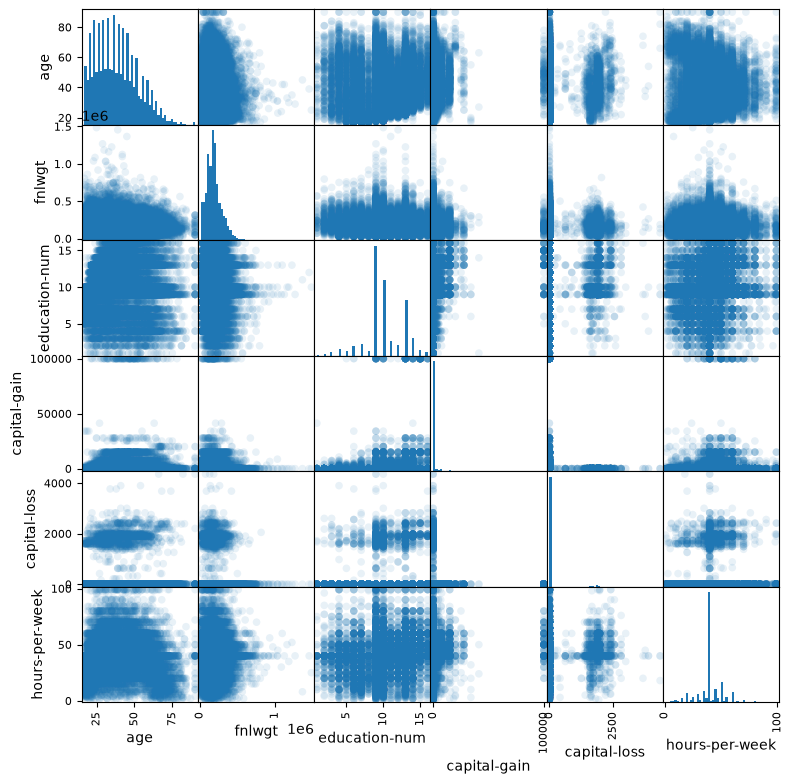

In [33]:
pd.plotting.scatter_matrix(df.select_dtypes(int), figsize=(9, 9), marker='o',hist_kwds={'bins': 50}, 
                           s=30, alpha=.1)
plt.show()

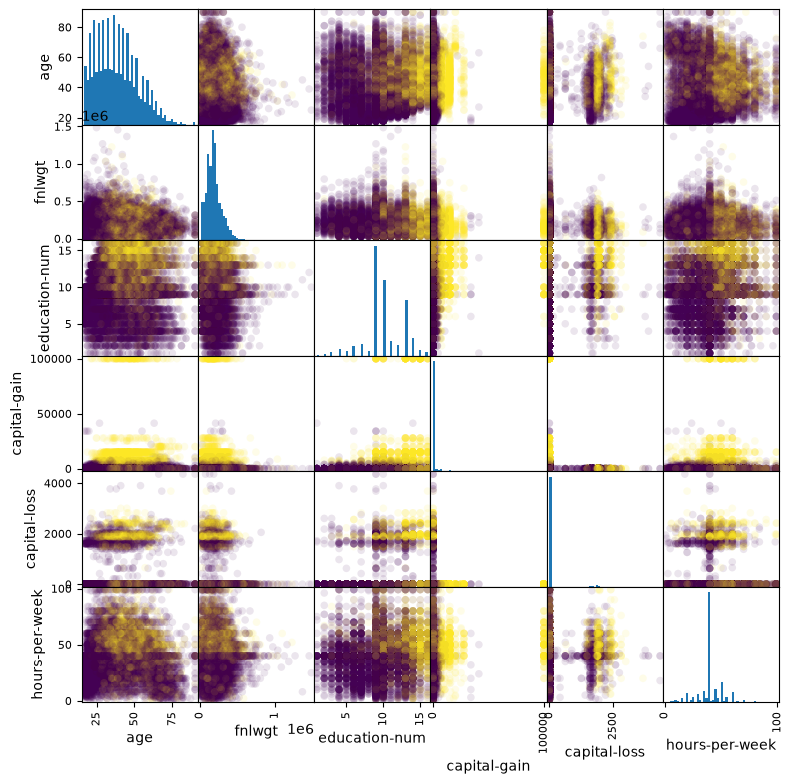

In [34]:
pd.plotting.scatter_matrix(df.select_dtypes(int), figsize=(9, 9),c = pd.get_dummies(df['gross-income']).iloc[:,1], 
                           marker='o',hist_kwds={'bins': 50}, s=30, alpha=.1)
plt.show()

## [Matplotlib cheatsheets!](https://github.com/matplotlib/cheatsheets)

The cheatsheets in this repo are excellent. Feel free to use them any time!

## Other great resources for visualization

DATA1500 - Data Visualization & Narrative (Course offered in the spring term)

https://www.data-to-viz.com/

https://pyviz.org/

# Mud card